# 3. Mesure des gains du tri automatique

Un projet IA n'est utile que s'il produit des **résultats mesurables**. Ce notebook estime ce que le tri automatique changerait pour le service client de TechDistrib, sur les 3 mois de test.

**Hypothèses** (mesurées dans les données, sauf la première qui est une hypothèse de fonctionnement) :
1. Un ticket trié automatiquement n'a plus besoin d'être lu par un agent pour être orienté : on économise son **temps de tri manuel** (mesuré : environ 4 minutes par ticket).
2. Les tickets dont le modèle n'est pas sûr restent triés par un agent, **avec le même taux d'erreur qu'aujourd'hui**.
3. Chaque erreur d'orientation retarde la première réponse du **retard moyen observé** pour une réorientation, à priorité égale.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analyse import charger_tickets
from modele_tri import SEUIL_CONFIANCE, decouper, entrainer, evaluer, predire

plt.rcParams.update({
    "figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 13, "axes.titleweight": "bold",
    "font.size": 11,
})
BLEU, ROUGE, GRIS = "#2563EB", "#DC2626", "#9CA3AF"
pd.set_option("display.precision", 3)

tickets = charger_tickets("../data/tickets_support.csv")

from gains import retard_moyen_reorientation, simuler, tableau_gains

In [2]:
_, test = decouper(tickets)
modeles = entrainer(tickets)
retard = retard_moyen_reorientation(tickets)
gains = simuler(test, predire(modeles, test["message"]), retard)

print(f"Retard moyen causé par une réorientation : {retard:.1f} heures ouvrées")
print(f"Tickets par mois : {gains['tickets_par_mois']:.0f}")
print(f"Tickets triés automatiquement : {gains['part_tri_auto']:.0%}")

Retard moyen causé par une réorientation : 6.7 heures ouvrées
Tickets par mois : 494
Tickets triés automatiquement : 88%


In [3]:
tableau_gains(gains)

,Aujourd'hui,Avec le tri IA,Écart
Indicateur,,,
Temps de tri par mois (heures),32.5,4.0,-28.5
Tickets mal orientés par mois,79.3,31.0,-48.3
Taux de tickets mal orientés (%),16.0,6.3,-9.8
SLA de 1re réponse respecté (%),74.3,78.5,4.2


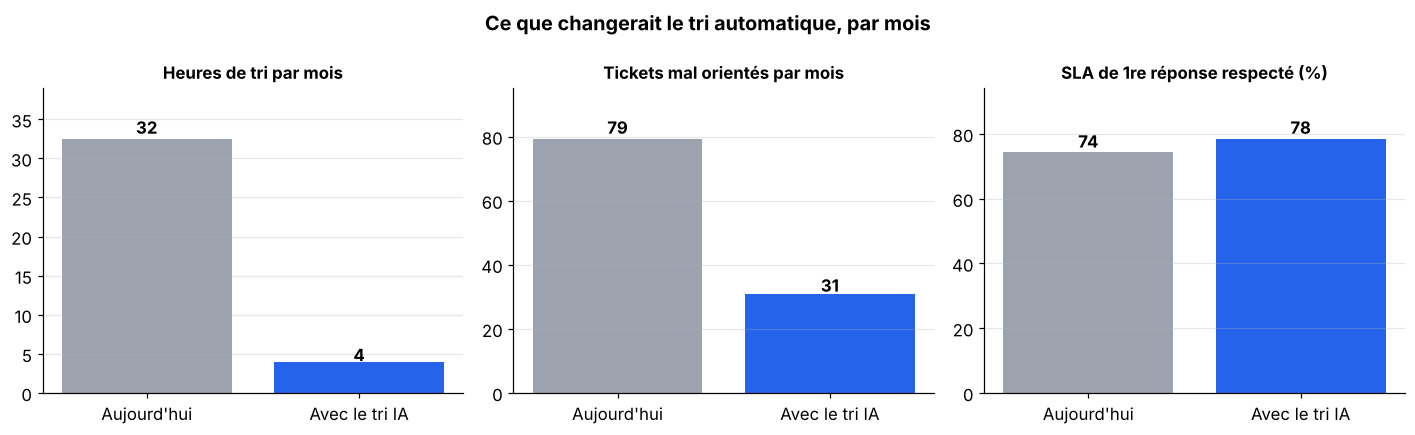

In [4]:
t = tableau_gains(gains)
indicateurs = [
    ("Temps de tri par mois (heures)", "Heures de tri par mois"),
    ("Tickets mal orientés par mois", "Tickets mal orientés par mois"),
    ("SLA de 1re réponse respecté (%)", "SLA de 1re réponse respecté (%)"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (cle, titre) in zip(axes, indicateurs):
    valeurs = [t.loc[cle, "Aujourd'hui"], t.loc[cle, "Avec le tri IA"]]
    ax.bar(["Aujourd'hui", "Avec le tri IA"], valeurs, color=[GRIS, BLEU])
    for i, v in enumerate(valeurs):
        ax.text(i, v * 1.02, f"{v:.0f}", ha="center", fontweight="bold")
    ax.set_title(titre, fontsize=11)
    ax.set_ylim(0, max(valeurs) * 1.2)
    ax.grid(axis="x", visible=False)
fig.suptitle("Ce que changerait le tri automatique, par mois", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("../reports/figures/gains.png", dpi=130, bbox_inches="tight")

In [5]:
print(f"Temps d'agent libéré : {gains['heures_tri_avant'] - gains['heures_tri_apres']:.0f} heures par mois")
print(f"Réorientations évitées : {gains['erreurs_avant'] - gains['erreurs_apres']:.0f} par mois")
print(f"Attente client évitée : {gains['heures_attente_evitees']:.0f} heures par mois")

Temps d'agent libéré : 29 heures par mois
Réorientations évitées : 48 par mois
Attente client évitée : 326 heures par mois


## Conclusion

Sur ce cas simulé, le tri automatique permettrait chaque mois :
- de **libérer près de 30 heures d'agent**, qui peuvent être consacrées à la résolution des tickets plutôt qu'à leur tri ;
- de **diviser par plus de deux le nombre de tickets mal orientés** (de 16 % à environ 6 %) ;
- d'**améliorer le respect du délai de première réponse** d'environ 4 points.

## Limites et prochaines étapes

- **Données simulées :** les résultats donnent un ordre de grandeur. Il faudrait les valider sur de vrais tickets.
- **Test pilote :** avant un déploiement complet, tester le tri automatique sur une seule équipe pendant quelques semaines et comparer les délais avec la période précédente.
- **Suivi dans le temps :** suivre chaque mois le taux d'erreur du modèle dans le reporting, et le réentraîner quand de nouveaux types de demandes apparaissent.
- **Intégration :** le tri pourrait être branché sur l'outil de ticketing par une automatisation (Make, Zapier ou une API) pour fonctionner sans intervention.